# Bab 7 — How to Picture Neural Networks: In Your Head and on Paper

**Acuan:** Trask, *Grokking Deep Learning*, Bab 7, hlm. 133–143. Bab ini terutama membangun cara berpikir dan notasi; notebook memberi rekonstruksi orisinal berupa diagram, tabel dimensi, dan satu forward pass yang saling konsisten.

**Tujuan belajar:** berpindah dari gambar koneksi satu per satu menuju abstraksi layer/matriks, lalu menghubungkan diagram, aljabar, dan kode.

## 1. Mengapa menyederhanakan gambar?

Pada jaringan kecil, setiap neuron dan garis bobot bisa digambar. Ketika ukuran layer ratusan unit, cara itu tidak lagi membantu. Abstraksi yang lebih berguna adalah **alur data**: layer input → matriks bobot → layer tersembunyi → matriks bobot → output. Kita tetap dapat melihat ukuran dan fungsi setiap blok tanpa menampilkan seluruh nilai bobot.

Istilah *correlation summarization* di buku adalah intuisi: training menyesuaikan representasi sehingga informasi yang berguna untuk target muncul pada layer berikutnya. Ini bukan jaminan statistik bahwa setiap bobot atau neuron punya makna tunggal, dan korelasi yang terlihat di training dapat gagal pada data baru.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)
X = np.array([[1., 0., 1.], [0., 1., 1.]])  # 2 contoh × 3 fitur
W01 = rng.normal(0, .3, size=(3, 4))       # 3 input → 4 hidden
W12 = rng.normal(0, .3, size=(4, 1))       # 4 hidden → 1 output
H = np.maximum(0, X @ W01)
Y_hat = H @ W12
for name, value in [('X', X), ('W01', W01), ('H', H), ('W12', W12), ('Y_hat', Y_hat)]:
    print(f'{name:6s}: {value.shape}')
assert H.shape == (2, 4) and Y_hat.shape == (2, 1)

X     : (2, 3)
W01   : (3, 4)
H     : (2, 4)
W12   : (4, 1)
Y_hat : (2, 1)


## 2. Dimensi menentukan arsitektur

Untuk batch $m$, jika input memiliki $d$ fitur, hidden layer $h$ unit, dan output $k$ nilai, maka $X:(m,d)$, $W_{01}:(d,h)$, $H:(m,h)$, dan $W_{12}:(h,k)$. Bentuk-bentuk ini bukan sekadar syarat NumPy: ia menyatakan berapa banyak informasi diwakili tiap layer dan berapa parameter yang perlu dilatih. Di sini ada $3\times4+4\times1=16$ bobot, tanpa bias.

Penamaan `layer_0`, `weights_0_1`, `layer_1`, dan `weights_1_2` membantu memisahkan **aktivasi** (berubah setiap input) dari **parameter** (tetap selama forward pass, berubah saat training).

Arsitektur: {'input': 3, 'hidden': 4, 'output': 1}
Jumlah bobot tanpa bias: 16


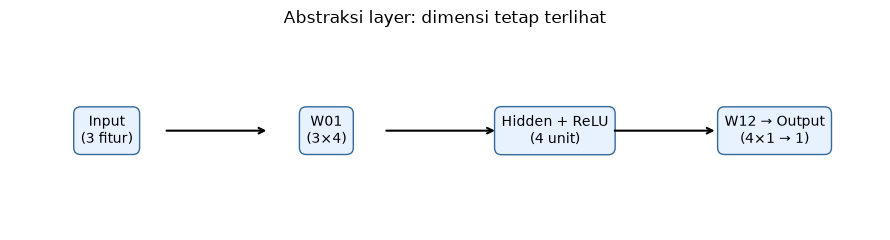

In [2]:
dimensions = {'input': X.shape[1], 'hidden': H.shape[1], 'output': Y_hat.shape[1]}
parameters = W01.size + W12.size
print('Arsitektur:', dimensions)
print('Jumlah bobot tanpa bias:', parameters)
assert parameters == 16

# Diagram blok, bukan semua koneksi neuron.
fig, ax = plt.subplots(figsize=(9, 2.5))
positions = [0, 2.5, 5.1, 7.6]
labels = ['Input\n(3 fitur)', 'W01\n(3×4)', 'Hidden + ReLU\n(4 unit)', 'W12 → Output\n(4×1 → 1)']
for x_pos, label in zip(positions, labels):
    ax.text(x_pos, 0, label, ha='center', va='center',
            bbox={'boxstyle': 'round,pad=.5', 'facecolor': '#e8f2ff', 'edgecolor': '#34699a'})
for left, right in zip(positions[:-1], positions[1:]):
    ax.annotate('', xy=(right-.65, 0), xytext=(left+.65, 0),
                arrowprops={'arrowstyle': '->', 'lw': 1.5})
ax.set_xlim(-1.1, 8.8); ax.set_ylim(-1, 1); ax.axis('off')
ax.set_title('Abstraksi layer: dimensi tetap terlihat')
plt.tight_layout(); plt.show()

## 3. Satu forward pass dalam tiga bahasa

**Diagram:** $X\rightarrow W_{01}\rightarrow\mathrm{ReLU}\rightarrow W_{12}\rightarrow\hat Y$. **Aljabar:** $H=\mathrm{ReLU}(XW_{01})$, $\hat Y=HW_{12}$. **Python:** operasi `@` untuk perkalian matriks dan `np.maximum` untuk ReLU. Ketiganya mendeskripsikan komputasi yang sama; pilihan representasi bergantung pada pertanyaan. Untuk debugging shape, aljabar/tabel lebih cepat; untuk menjelaskan alur konsep, diagram lebih mudah.

In [3]:
single_x = X[0]
manual_hidden = np.array([max(0, sum(single_x[j] * W01[j, h] for j in range(3)))
                          for h in range(4)])
manual_output = sum(manual_hidden[h] * W12[h, 0] for h in range(4))
print('Penelusuran satu contoh:')
print('Input:', single_x)
print('Hidden:', manual_hidden.round(4))
print('Output manual / matrix:', round(manual_output, 5), round(float(Y_hat[0, 0]), 5))
assert np.allclose(manual_hidden, H[0])
assert np.isclose(manual_output, Y_hat[0, 0])

Penelusuran satu contoh:
Input: [1. 0. 1.]
Hidden: [0.2343 0.     0.8374 0.    ]
Output manual / matrix: -0.04741 -0.04741


## 4. Apa yang disembunyikan abstraksi?

Diagram blok memudahkan melihat *arsitektur*, tetapi bisa menyembunyikan skala nilai, neuron ReLU yang selalu mati, dan distribusi gradien. Ketika model tidak belajar, kembali ke pemeriksaan rinci: shape, nilai aktivasi, gradien, dan loss pada contoh kecil. Visualisasi yang baik harus membantu menjawab pertanyaan teknis tertentu, bukan hanya terlihat menarik.

### Ringkasan

- Arsitektur adalah pilihan jumlah/jenis layer serta koneksi antar-layer.
- Dimensi layer menentukan dimensi matriks bobot dan jumlah parameter.
- Diagram, persamaan, dan kode sebaiknya saling cocok; ketidaksesuaian adalah petunjuk bug.
- Bab ini tidak memperkenalkan model baru; fokusnya adalah cara memikirkan dan menjelaskan model yang telah dibangun.